# Computer Vision Ödevi: Oxford-IIIT Pet Sınıflandırma (ResNet18)
**Çalışma sırası:** Çalışma zamanı > Çalışma zamanı türünü değiştir > **T4 GPU**, sonra hücreleri yukarıdan aşağı çalıştır.

Görev: Görüntü sınıflandırma | Veri seti: Oxford-IIIT Pet (37 sınıf) | Model: ResNet18 (ImageNet ön-eğitimli, transfer learning)

## 1) Kurulum ve ayarlar

In [ ]:
!pip -q install gradio scikit-learn
import torch, torch.nn as nn, time, random, numpy as np
import matplotlib.pyplot as plt
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, Subset

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Cihaz:', device, '|', torch.cuda.get_device_name(0) if device.type=='cuda' else 'CPU (GPU açmayı unutma!)')

# Hiperparametreler (rapora bunları yaz)
BATCH_SIZE = 32
EPOCHS = 8
LR = 3e-4
WEIGHT_DECAY = 1e-4
IMG_SIZE = 224

Cihaz: cuda | Tesla T4


## 2) Veri seti ve train / val / test ayrımı
`trainval` (3680 görüntü) %85 train, %15 validation olarak bölünür. Resmi `test` (3669 görüntü) kümesi sadece en sonda kullanılır.

In [ ]:
mean, std = [0.485,0.456,0.406], [0.229,0.224,0.225]
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7,1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(0.2,0.2,0.2),
    transforms.ToTensor(), transforms.Normalize(mean,std)])
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE,IMG_SIZE)),
    transforms.ToTensor(), transforms.Normalize(mean,std)])

full_train = datasets.OxfordIIITPet('data', split='trainval', transform=train_tf, download=True)
full_val   = datasets.OxfordIIITPet('data', split='trainval', transform=eval_tf)
test_ds    = datasets.OxfordIIITPet('data', split='test', transform=eval_tf, download=True)

g = torch.Generator().manual_seed(SEED)
idx = torch.randperm(len(full_train), generator=g).tolist()
n_val = int(0.15*len(idx))
train_ds = Subset(full_train, idx[n_val:])
val_ds   = Subset(full_val,   idx[:n_val])

train_dl = DataLoader(train_ds, BATCH_SIZE, shuffle=True,  num_workers=2)
val_dl   = DataLoader(val_ds,   BATCH_SIZE, shuffle=False, num_workers=2)
test_dl  = DataLoader(test_ds,  BATCH_SIZE, shuffle=False, num_workers=2)
classes = full_train.classes
print('Train/Val/Test:', len(train_ds), len(val_ds), len(test_ds), '| Sınıf sayısı:', len(classes))

100%|██████████| 792M/792M [00:31<00:00, 25.0MB/s]
100%|██████████| 19.2M/19.2M [00:02<00:00, 8.82MB/s]


Train/Val/Test: 3128 552 3669 | Sınıf sayısı: 37


## 3) Model, loss, optimizer
- **ResNet18**: Küçük veri setinde ImageNet ağırlıklarıyla transfer learning iyi sonuç verir. Son katman 37 sınıfa göre değiştirilir.
- **Çıkış**: 37 logit, Softmax tahmin sırasında uygulanır.
- **Loss**: CrossEntropyLoss (çok sınıflı sınıflandırma).
- **Optimizer**: AdamW (weight decay ile düzenlileştirme), **Scheduler**: CosineAnnealing.

In [ ]:
model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
model.fc = nn.Linear(model.fc.in_features, len(classes))
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
print('Parametre sayısı:', sum(p.numel() for p in model.parameters())/1e6, 'M')

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 170MB/s]


Parametre sayısı: 11.195493 M


## 4) Eğitim (en iyi validation modeli kaydedilir)

Epoch 1/8 | train loss 1.189 acc 0.697 | val loss 0.637 acc 0.830
Epoch 2/8 | train loss 0.362 acc 0.914 | val loss 0.687 acc 0.810
Epoch 3/8 | train loss 0.208 acc 0.950 | val loss 0.604 acc 0.824
Epoch 4/8 | train loss 0.114 acc 0.976 | val loss 0.433 acc 0.853
Epoch 5/8 | train loss 0.053 acc 0.992 | val loss 0.372 acc 0.893
Epoch 6/8 | train loss 0.038 acc 0.995 | val loss 0.317 acc 0.918
Epoch 7/8 | train loss 0.026 acc 0.996 | val loss 0.310 acc 0.917
Epoch 8/8 | train loss 0.020 acc 0.998 | val loss 0.298 acc 0.920

Eğitim süresi: 3.6 dk | En iyi val acc: 0.9203


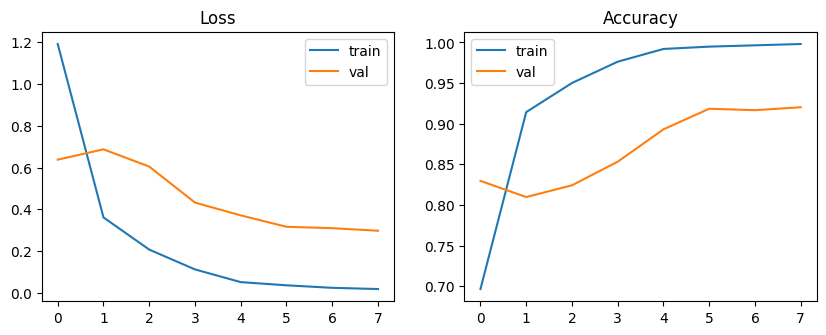

In [ ]:
def evaluate(loader):
    model.eval(); preds, labels, loss_sum = [], [], 0
    with torch.no_grad():
        for x,y in loader:
            x,y = x.to(device), y.to(device)
            out = model(x)
            loss_sum += criterion(out,y).item()*x.size(0)
            preds += out.argmax(1).cpu().tolist(); labels += y.cpu().tolist()
    preds, labels = np.array(preds), np.array(labels)
    return loss_sum/len(labels), (preds==labels).mean(), preds, labels

history = {'tr_loss':[], 'val_loss':[], 'tr_acc':[], 'val_acc':[]}
best_val, t0 = 0, time.time()
for ep in range(EPOCHS):
    model.train(); tl, correct, n = 0, 0, 0
    for x,y in train_dl:
        x,y = x.to(device), y.to(device)
        optimizer.zero_grad()
        out = model(x); loss = criterion(out,y)
        loss.backward(); optimizer.step()
        tl += loss.item()*x.size(0); correct += (out.argmax(1)==y).sum().item(); n += x.size(0)
    scheduler.step()
    vl, va, _, _ = evaluate(val_dl)
    history['tr_loss'].append(tl/n); history['tr_acc'].append(correct/n)
    history['val_loss'].append(vl);  history['val_acc'].append(va)
    if va > best_val:
        best_val = va; torch.save(model.state_dict(), 'best_model.pt')
    print(f'Epoch {ep+1}/{EPOCHS} | train loss {tl/n:.3f} acc {correct/n:.3f} | val loss {vl:.3f} acc {va:.3f}')
train_time = time.time()-t0
print(f'\nEğitim süresi: {train_time/60:.1f} dk | En iyi val acc: {best_val:.4f}')

fig,ax = plt.subplots(1,2,figsize=(10,3.5))
ax[0].plot(history['tr_loss'],label='train'); ax[0].plot(history['val_loss'],label='val'); ax[0].set_title('Loss'); ax[0].legend()
ax[1].plot(history['tr_acc'],label='train'); ax[1].plot(history['val_acc'],label='val'); ax[1].set_title('Accuracy'); ax[1].legend()
plt.show()

## 5) Test kümesi değerlendirmesi (Accuracy, Precision, Recall, F1, tahmin süresi)

In [ ]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report
model.load_state_dict(torch.load('best_model.pt')); model.eval()
_, _, preds, labels = evaluate(test_dl)
acc = accuracy_score(labels, preds)
p,r,f1,_ = precision_recall_fscore_support(labels, preds, average='macro', zero_division=0)
print(f'Test Accuracy: {acc:.4f}\nPrecision (macro): {p:.4f}\nRecall (macro): {r:.4f}\nF1 (macro): {f1:.4f}')

# Tahmin süresi: tek görüntü, ortalama
x = torch.randn(1,3,IMG_SIZE,IMG_SIZE).to(device)
with torch.no_grad():
    for _ in range(10): model(x)
    if device.type=='cuda': torch.cuda.synchronize()
    t=time.time()
    for _ in range(100): model(x)
    if device.type=='cuda': torch.cuda.synchronize()
inf_ms = (time.time()-t)/100*1000
print(f'Tahmin süresi: {inf_ms:.2f} ms / görüntü')

# En çok karıştırılan sınıflar (yorum için işine yarar)
from collections import Counter
conf = Counter((classes[a],classes[b]) for a,b in zip(labels,preds) if a!=b)
print('\nEn sık hatalar (gerçek -> tahmin):')
for (a,b),c in conf.most_common(5): print(f'  {a} -> {b}: {c}')
print('\n', classification_report(labels, preds, target_names=classes, zero_division=0))

Test Accuracy: 0.8839
Precision (macro): 0.8849
Recall (macro): 0.8834
F1 (macro): 0.8816
Tahmin süresi: 2.80 ms / görüntü

En sık hatalar (gerçek -> tahmin):
  American Pit Bull Terrier -> Staffordshire Bull Terrier: 16
  Ragdoll -> Birman: 15
  American Pit Bull Terrier -> American Bulldog: 14
  American Pit Bull Terrier -> German Shorthaired: 13
  Egyptian Mau -> Bengal: 12

                             precision    recall  f1-score   support

                Abyssinian       0.86      0.91      0.88        98
          American Bulldog       0.74      0.86      0.79       100
 American Pit Bull Terrier       0.78      0.45      0.57       100
              Basset Hound       0.84      0.90      0.87       100
                    Beagle       0.83      0.86      0.84       100
                    Bengal       0.79      0.95      0.86       100
                    Birman       0.77      0.89      0.83       100
                    Bombay       0.91      0.93      0.92        88
     

## 6) Gradio uygulaması (Deployment)
Çıkan `public URL` linkini rapora/ekran görüntüsüne ekleyebilirsin.

In [ ]:
import gradio as gr
def predict(img):
    x = eval_tf(img.convert('RGB')).unsqueeze(0).to(device)
    with torch.no_grad():
        probs = torch.softmax(model(x),1)[0].cpu()
    top = probs.topk(5)
    return {classes[i]: float(p) for p,i in zip(top.values, top.indices)}

demo = gr.Interface(fn=predict, inputs=gr.Image(type='pil', label='Evcil hayvan fotoğrafı'),
                    outputs=gr.Label(num_top_classes=5, label='Tahmin'),
                    title='Pet Breed Classifier (ResNet18)',
                    description='Kedi/köpek fotoğrafı yükle, 37 ırktan hangisi olduğunu tahmin edeyim.')
demo.close()
demo.launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://7310424eb9ef533d0e.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://7310424eb9ef533d0e.gradio.live


## 7) Kendi telefon fotoğraflarınla test
5 fotoğraf yükle. Dosya adını **gerçek ırk adıyla** kaydedersen (ör. `Persian.jpg`, `pug.jpg`) gerçek etiketle karşılaştırma otomatik yapılır. Ev hayvanı yoksa internetten değil, mümkünse sokaktaki/arkadaşın hayvanını çek.

Saving british_shorthair.webp to british_shorthair.webp
Saving turk_angora.jpg to turk_angora.jpg
Saving tekir_sokak_kedisi.webp to tekir_sokak_kedisi.webp
Saving turuncu_tekir.webp to turuncu_tekir.webp
Saving melez_mavi_gozlu.jpg to melez_mavi_gozlu.jpg


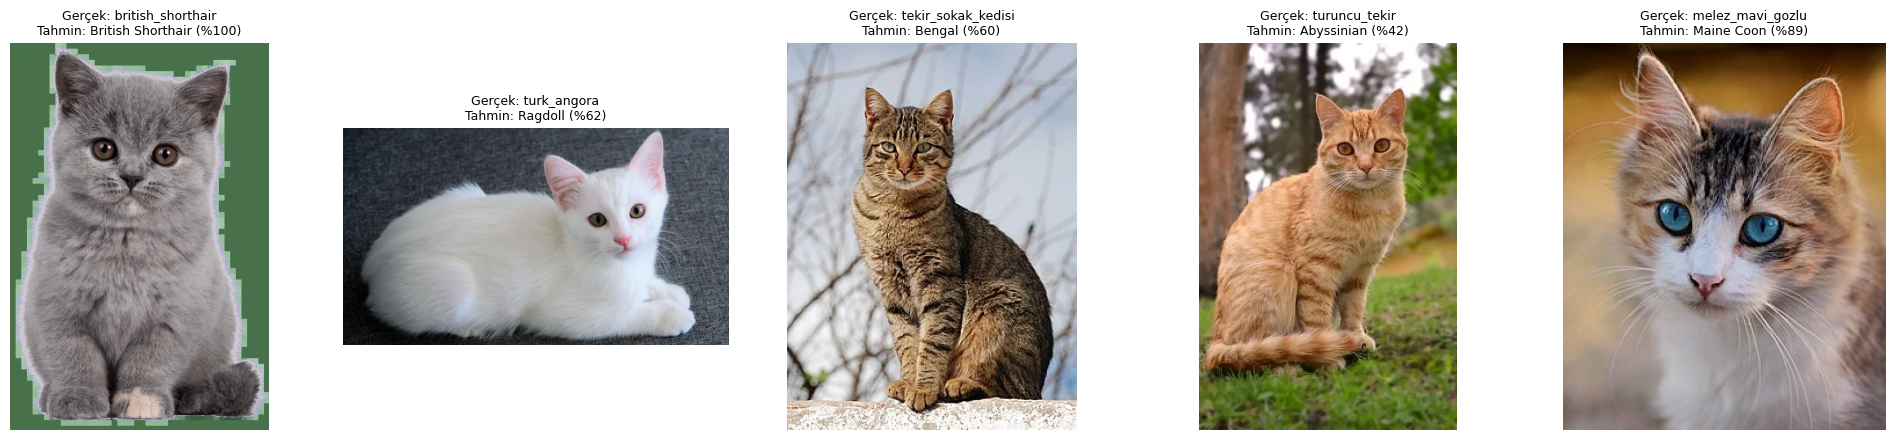

In [ ]:
from google.colab import files
from PIL import Image
import os
up = files.upload()
paths = list(up.keys())[:5]
fig, axes = plt.subplots(1, len(paths), figsize=(4*len(paths),4.5))
axes = np.atleast_1d(axes)
for ax,pth in zip(axes,paths):
    img = Image.open(pth).convert('RGB')
    res = predict(img); top = max(res, key=res.get)
    ax.imshow(img); ax.axis('off')
    true = os.path.splitext(pth)[0]
    ax.set_title(f'Gerçek: {true}\nTahmin: {top} (%{res[top]*100:.0f})', fontsize=9)
plt.tight_layout(); plt.show()

## 8) Rapor tablosu için özet

In [ ]:
print(f'''Project Title        : Pet Breed Classification with ResNet18
Problem / Task       : Image classification (37 classes)
Dataset              : Oxford-IIIT Pet
Dataset URL          : https://www.robots.ox.ac.uk/~vgg/data/pets/
Model Architecture   : ResNet18 (ImageNet pretrained, fine-tuned)
Input Size           : {IMG_SIZE}x{IMG_SIZE}x3
Hyperparameters      : lr={LR}, batch={BATCH_SIZE}, epochs={EPOCHS}, weight decay={WEIGHT_DECAY}, cosine LR schedule
Optimizer            : AdamW
Activation / Output  : ReLU (hidden), Softmax (output, 37 classes)
Loss Function        : CrossEntropyLoss
Evaluation Metrics   : Accuracy, Precision, Recall, F1 (macro)
Training Environment : Google Colab, {torch.cuda.get_device_name(0) if device.type=='cuda' else 'CPU'}, PyTorch {torch.__version__}
Best Performance     : Test acc {acc:.4f}, F1 {f1:.4f} (val acc {best_val:.4f}); train time {train_time/60:.1f} dk
Inference Time       : {inf_ms:.2f} ms / image
Deployment Technology: Gradio
Repository           : (GitHub linkini buraya yaz)''')

Project Title        : Pet Breed Classification with ResNet18
Problem / Task       : Image classification (37 classes)
Dataset              : Oxford-IIIT Pet
Dataset URL          : https://www.robots.ox.ac.uk/~vgg/data/pets/
Model Architecture   : ResNet18 (ImageNet pretrained, fine-tuned)
Input Size           : 224x224x3
Hyperparameters      : lr=0.0003, batch=32, epochs=8, weight decay=0.0001, cosine LR schedule
Optimizer            : AdamW
Activation / Output  : ReLU (hidden), Softmax (output, 37 classes)
Loss Function        : CrossEntropyLoss
Evaluation Metrics   : Accuracy, Precision, Recall, F1 (macro)
Training Environment : Google Colab, Tesla T4, PyTorch 2.14.1+cu130
Best Performance     : Test acc 0.8839, F1 0.8816 (val acc 0.9203); train time 3.6 dk
Inference Time       : 2.80 ms / image
Deployment Technology: Gradio
Repository           : (GitHub linkini buraya yaz)
